In [118]:
import json
import os
from pathlib import Path
import sys

import h3
import h3pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydeck as pdk
import seaborn as sns
from shapely.geometry import shape
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import average_precision_score
import tensorflow as tf
from tqdm.auto import tqdm

sns.set()

In [65]:
sys.path.append('..')
from lib.models.tf_gp_model import TFGeoPriorModel
from lib.models.encoders import CoordEncoder

In [112]:
GEOMODEL_PATH = "/home/alex/export_eval_models/model_exports/tf_geoprior_2_20_r6_elevation.h5"
ELEVATION_RASTER_PATH = "/home/alex/sinr/data/env/elev_scaled.npy"
INPUT_ENCODING = "sinusoidal"
TAX_2_20_FILE = "/data-ssd/alex/datasets/vision-export-20250119070012-aka-2.20/taxonomy.csv"
SPATIAL_DATA_2_20_FILE = "/data-ssd/alex/datasets/vision-export-20250119070012-aka-2.20/spatial_data.parquet"
SNT_PATH = "/home/alex/sinr/data/eval/snt/snt_res_5.npy"
IUCN_PATH = "/home/alex/sinr/data/eval/iucn/iucn_res_5.json"
GRID_THRESHOLDS = "/home/alex/inatVisionApi/geo_model_eval_output/v2_20_grid/thresholds.csv"

In [67]:
model = TFGeoPriorModel(GEOMODEL_PATH)
raster = np.load(ELEVATION_RASTER_PATH).astype(np.float32)
encoder = CoordEncoder(INPUT_ENCODING, raster=raster)
tax_2_20 = pd.read_csv(TAX_2_20_FILE)
inat_standard_thresholds = pd.read_csv(GRID_THRESHOLDS)

2025-04-24 08:06:41.130960: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:274] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2025-04-24 08:06:41.130998: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:129] retrieving CUDA diagnostic information for host: euclid
2025-04-24 08:06:41.131009: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:136] hostname: euclid
2025-04-24 08:06:41.131157: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:159] libcuda reported version is: 550.120.0
2025-04-24 08:06:41.131188: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:163] kernel reported version is: 550.120.0
2025-04-24 08:06:41.131195: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:241] kernel version seems to match DSO: 550.120.0


In [3]:
eval_standard = pd.read_csv(
    "/home/alex/inatVisionApi/geo_model_eval_output/v2_20_grid/tf_env_eval.csv"
)
eval_standard.head()

,Unnamed: 0,taxon_id,prauc,p,r,f1,taxon_range_area
0,0,62,0.888708,0.809641,0.841660,0.825340,1.172839e+07
1,1,144,0.796954,0.597083,0.757225,0.667686,1.531330e+06
2,2,151,0.785377,0.777593,0.583074,0.666430,2.844910e+06
3,3,156,0.634734,0.270764,0.981437,0.424433,2.193431e+06
4,4,162,0.864961,0.789783,0.913676,0.847224,1.716506e+07


In [37]:
thresh_standard = pd.read_csv(
    "/home/alex/inatVisionApi/geo_model_eval_output/v2_20_grid/thresholds.csv"
)

In [38]:
eval_lpt_r = pd.read_csv(
    "/home/alex/inatVisionApi/geo_model_eval_output/v2_20_grid_lpt_r_thresh/tf_env_eval_test.csv"
)
thresh_lptr = pd.read_csv(
    "/home/alex/inatVisionApi/geo_model_eval_output/v2_20_grid_lpt_r_thresh/thresholds.csv"
)
eval_lpt_r.head()

,Unnamed: 0,taxon_id,prauc,p,r,f1,taxon_range_area
0,0,62,0.888708,0.757251,0.894642,0.820232,1.172839e+07
1,1,144,0.796954,0.611641,0.741040,0.670152,1.531330e+06
2,2,151,0.785377,0.107140,1.000000,0.193545,2.844910e+06
3,3,156,0.634734,0.478510,0.808717,0.601260,2.193431e+06
4,4,162,0.864961,0.854700,0.850557,0.852623,1.716506e+07


In [12]:
evals = pd.merge(
    eval_standard,
    eval_lpt_r,
    left_on="taxon_id",
    right_on="taxon_id",
    suffixes=["_standard", "_lptr"],
)
evals

,Unnamed: 0_standard,taxon_id,prauc_standard,p_standard,r_standard,f1_standard,taxon_range_area_standard,Unnamed: 0_lptr,prauc_lptr,p_lptr,r_lptr,f1_lptr,taxon_range_area_lptr
0,0,62,0.888708,0.809641,0.841660,0.825340,1.172839e+07,0,0.888708,0.757251,0.894642,0.820232,1.172839e+07
1,1,144,0.796954,0.597083,0.757225,0.667686,1.531330e+06,1,0.796954,0.611641,0.741040,0.670152,1.531330e+06
2,2,151,0.785377,0.777593,0.583074,0.666430,2.844910e+06,2,0.785377,0.107140,1.000000,0.193545,2.844910e+06
3,3,156,0.634734,0.270764,0.981437,0.424433,2.193431e+06,3,0.634734,0.478510,0.808717,0.601260,2.193431e+06
4,4,162,0.864961,0.789783,0.913676,0.847224,1.716506e+07,4,0.864961,0.854700,0.850557,0.852623,1.716506e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6231,6231,348813,0.881711,0.763052,0.822511,0.791667,4.089447e+05,6231,0.881711,0.785388,0.744589,0.764444,4.089447e+05
6232,6232,48639,0.674422,0.551042,0.712938,0.621622,1.313580e+06,6232,0.674422,0.309599,0.925876,0.464032,1.313580e+06
6233,6233,352474,0.769642,0.574803,0.774536,0.659887,6.674120e+05,6233,0.769642,0.789091,0.575597,0.665644,6.674120e+05
6234,6234,154564,0.773232,0.846827,0.294930,0.437492,3.076291e+07,6234,0.773232,0.738891,0.633481,0.682138,3.076291e+07


In [14]:
evals["f1_diff"] = evals["f1_standard"] - evals["f1_lptr"]

In [17]:
evals.dropna().sort_values("f1_diff")

,Unnamed: 0_standard,taxon_id,prauc_standard,p_standard,r_standard,f1_standard,taxon_range_area_standard,Unnamed: 0_lptr,prauc_lptr,p_lptr,r_lptr,f1_lptr,taxon_range_area_lptr,f1_diff
5653,5653,105923,0.874911,0.899477,0.093661,0.169656,2.081989e+08,5653,0.874911,0.828415,0.880498,0.853663,2.081989e+08,-0.684007
2181,2181,4341,0.865788,1.000000,0.016020,0.031535,2.099604e+06,2181,0.865788,0.863145,0.606239,0.712234,2.099604e+06,-0.680699
5669,5669,96760,0.844621,0.998420,0.042618,0.081748,2.099374e+08,5669,0.844621,0.819689,0.685151,0.746406,2.099374e+08,-0.664658
3648,3648,28932,0.864176,0.875332,0.072799,0.134420,8.024877e+06,3648,0.864176,0.856793,0.694242,0.767000,8.024877e+06,-0.632580
4606,4606,41494,0.873011,0.983291,0.151554,0.262630,2.674038e+08,4606,0.873011,0.804216,0.840475,0.821946,2.674038e+08,-0.559316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2272,2272,3776,0.989244,0.976812,0.936111,0.956028,6.373165e+05,2272,0.989244,0.070012,1.000000,0.130862,6.373165e+05,0.825167
3566,3566,33622,0.903770,0.750000,1.000000,0.857143,1.062194e+04,3566,0.903770,0.008571,1.000000,0.016997,1.062194e+04,0.840146
49,49,1158,0.840696,1.000000,0.733333,0.846154,2.655485e+04,49,0.840696,0.000720,1.000000,0.001439,2.655485e+04,0.844715
297,297,6963,0.937448,0.833333,0.909091,0.869565,1.947356e+04,297,0.937448,0.000908,1.000000,0.001814,1.947356e+04,0.867752


<Axes: >

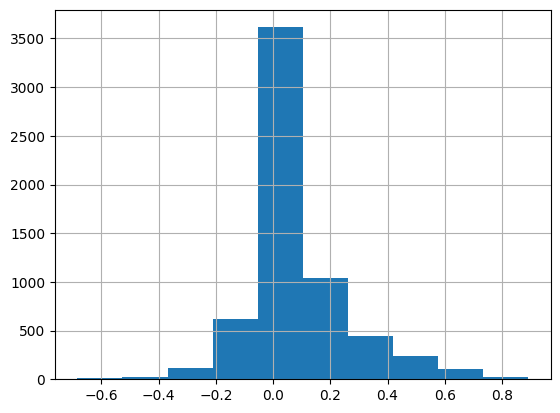

In [18]:
evals.f1_diff.hist()

In [19]:
evals[["taxon_range_area_lptr", "f1_diff"]]

,taxon_range_area_lptr,f1_diff
0,1.172839e+07,0.005108
1,1.531330e+06,-0.002466
2,2.844910e+06,0.472885
3,2.193431e+06,-0.176827
4,1.716506e+07,-0.005399
...,...,...
6231,4.089447e+05,0.027222
6232,1.313580e+06,0.157589
6233,6.674120e+05,-0.005757
6234,3.076291e+07,-0.244646


In [21]:
evals.dropna().corr()

,Unnamed: 0_standard,taxon_id,prauc_standard,p_standard,r_standard,f1_standard,taxon_range_area_standard,Unnamed: 0_lptr,prauc_lptr,p_lptr,r_lptr,f1_lptr,taxon_range_area_lptr,f1_diff
Unnamed: 0_standard,1.000000,0.041396,-0.238216,-0.065891,-0.331799,-0.300153,0.125421,1.000000,-0.238216,-0.207111,-0.062724,-0.262713,0.125421,0.045015
taxon_id,0.041396,1.000000,-0.039767,-0.028493,-0.021560,-0.039731,-0.043890,0.041396,-0.039767,-0.013364,-0.038569,-0.025471,-0.043890,-0.006918
prauc_standard,-0.238216,-0.039767,1.000000,0.695843,0.495653,0.838223,0.023850,-0.238216,1.000000,0.668948,0.121174,0.697549,0.023850,-0.075720
p_standard,-0.065891,-0.028493,0.695843,1.000000,-0.103760,0.580572,0.074422,-0.065891,0.695843,0.626912,-0.158046,0.566245,0.074422,-0.167475
r_standard,-0.331799,-0.021560,0.495653,-0.103760,1.000000,0.670548,-0.124095,-0.331799,0.495653,0.247800,0.407380,0.371351,-0.124095,0.197793
f1_standard,-0.300153,-0.039731,0.838223,0.580572,0.670548,1.000000,-0.050359,-0.300153,0.838223,0.618490,0.207740,0.695116,-0.050359,0.099376
taxon_range_area_standard,0.125421,-0.043890,0.023850,0.074422,-0.124095,-0.050359,1.000000,0.125421,0.023850,0.096017,-0.000493,0.091126,1.000000,-0.179586
Unnamed: 0_lptr,1.000000,0.041396,-0.238216,-0.065891,-0.331799,-0.300153,0.125421,1.000000,-0.238216,-0.207111,-0.062724,-0.262713,0.125421,0.045015
prauc_lptr,-0.238216,-0.039767,1.000000,0.695843,0.495653,0.838223,0.023850,-0.238216,1.000000,0.668948,0.121174,0.697549,0.023850,-0.075720
p_lptr,-0.207111,-0.013364,0.668948,0.626912,0.247800,0.618490,0.096017,-0.207111,0.668948,1.000000,-0.400204,0.926782,0.096017,-0.626257


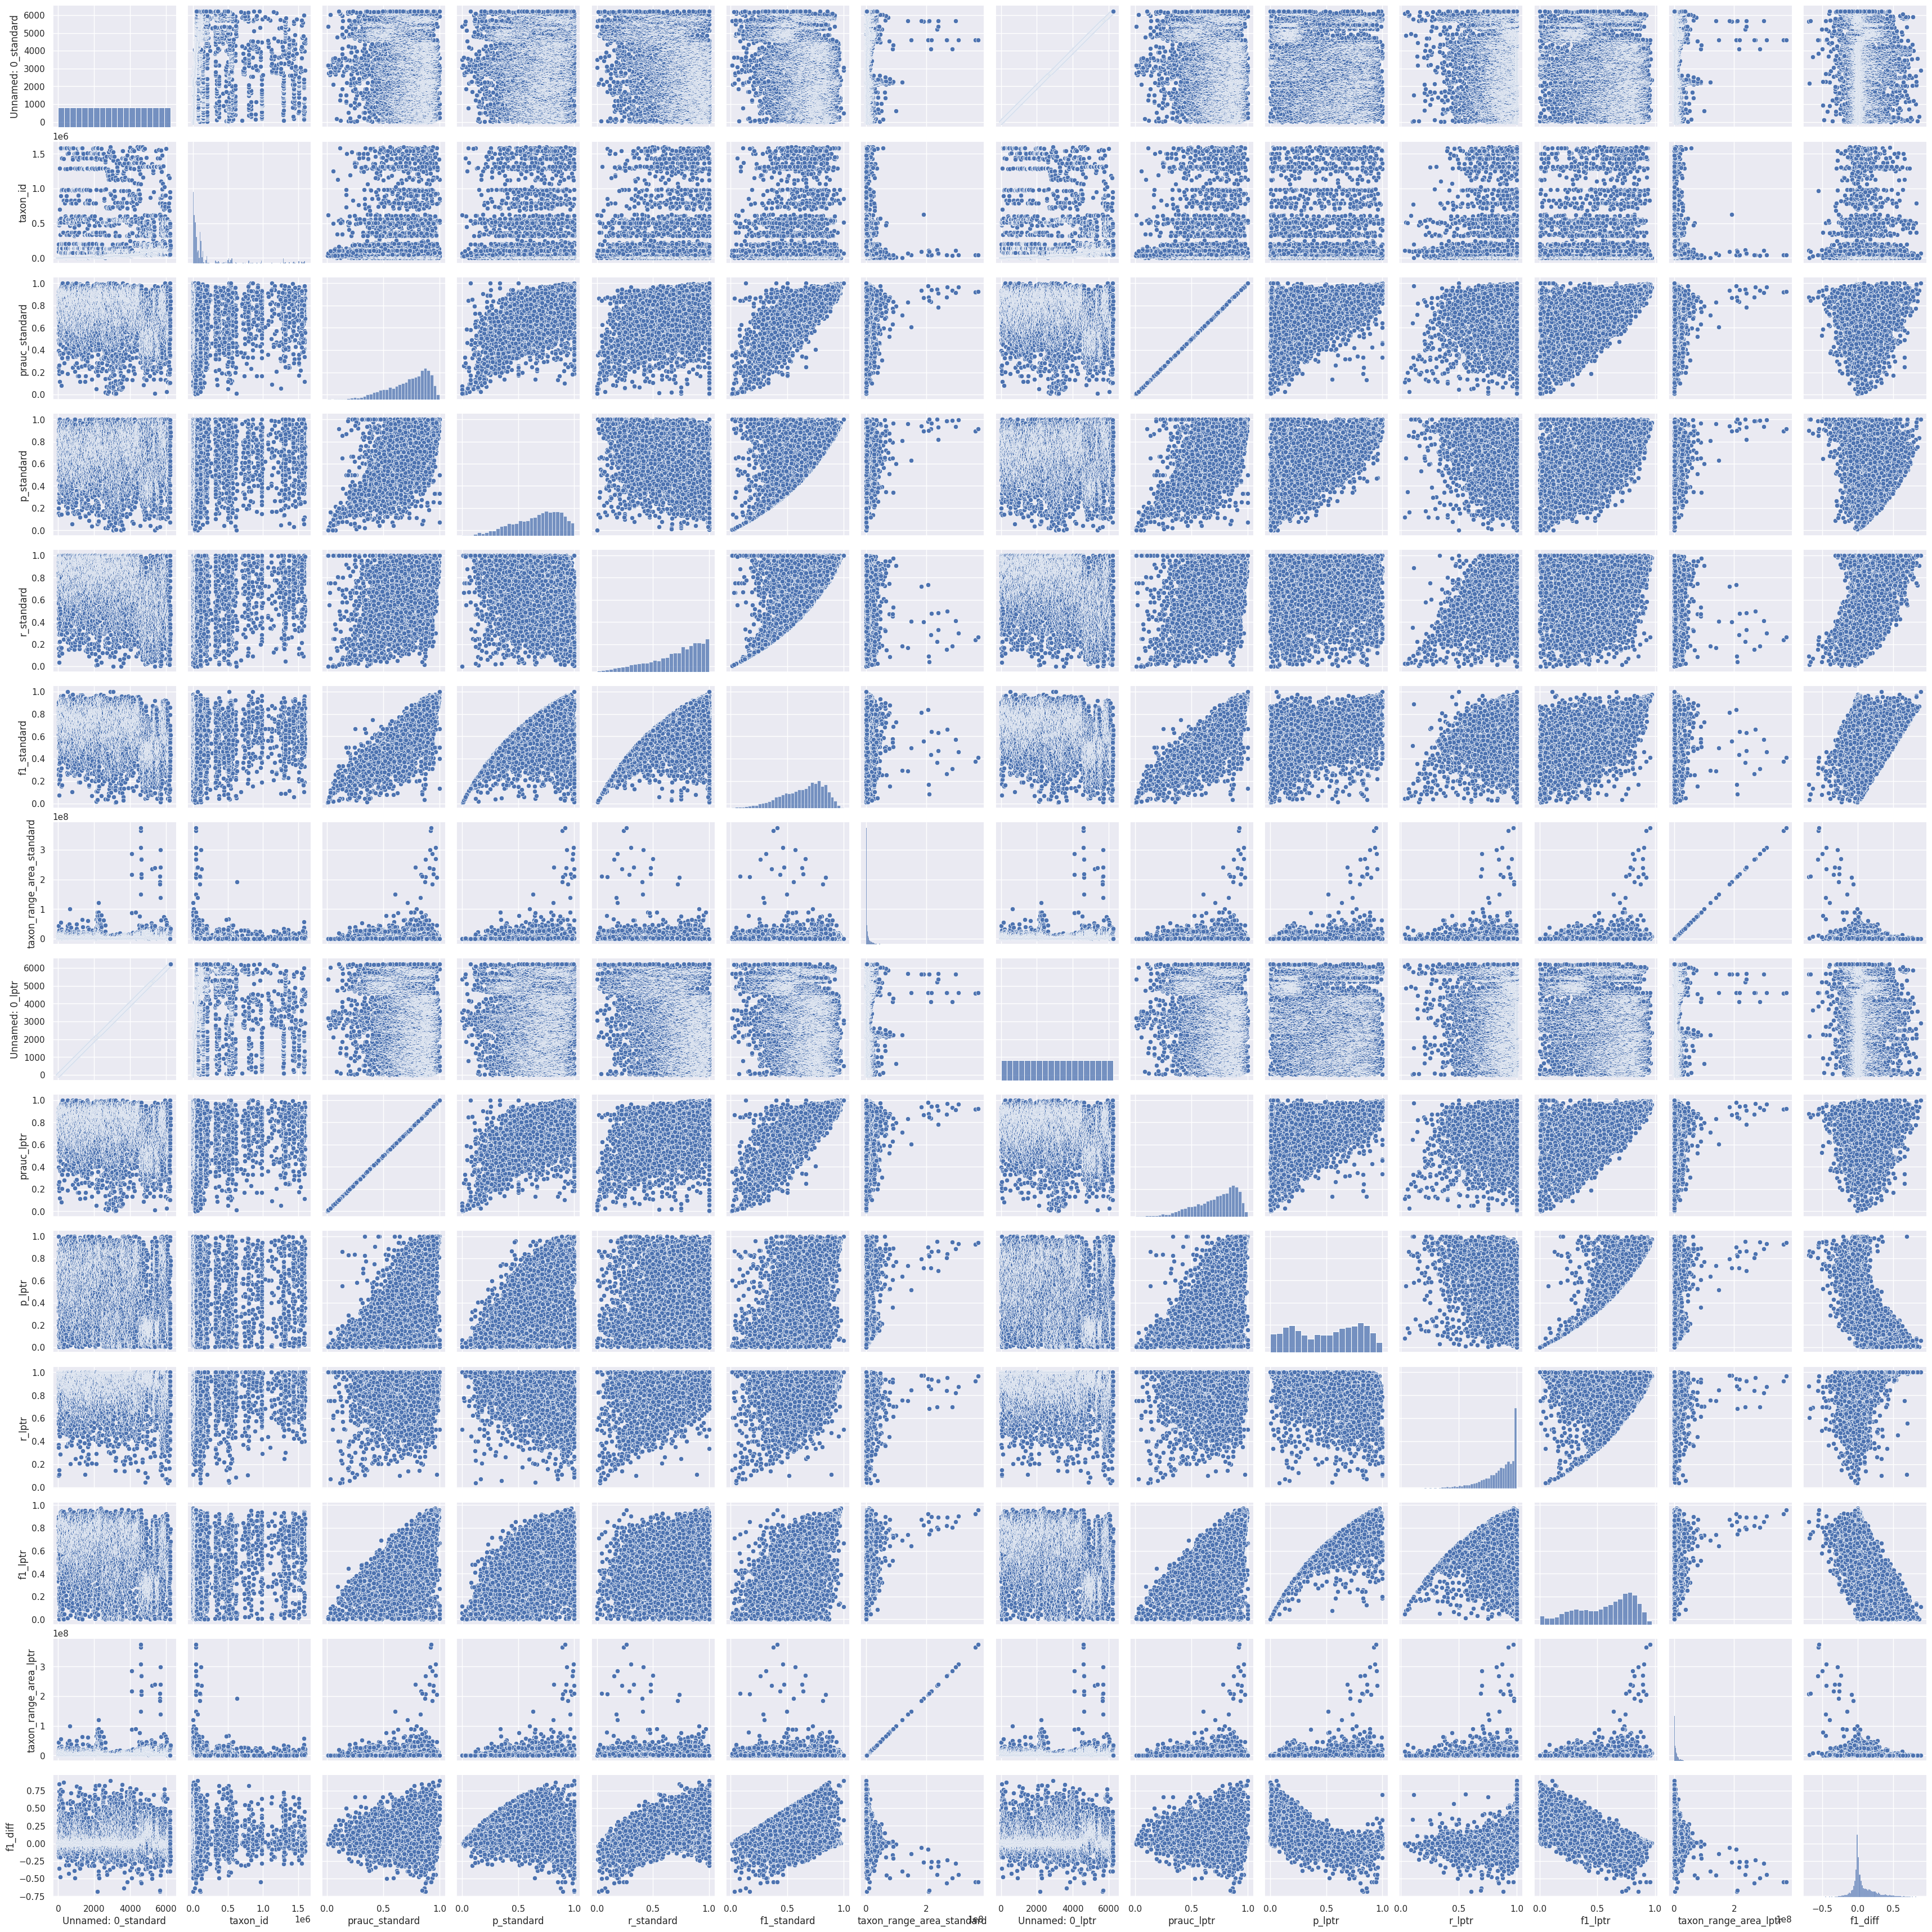

In [25]:
sns.pairplot(evals)

In [29]:
evals.dropna().sort_values("taxon_range_area_lptr")

,Unnamed: 0_standard,taxon_id,prauc_standard,p_standard,r_standard,f1_standard,taxon_range_area_standard,Unnamed: 0_lptr,prauc_lptr,p_lptr,r_lptr,f1_lptr,taxon_range_area_lptr,f1_diff
3415,3415,38718,0.250000,0.500000,1.000000,0.666667,1.770324e+03,3415,0.250000,0.003731,1.000000,0.007435,1.770324e+03,0.659232
3027,3027,733752,0.166667,0.333333,1.000000,0.500000,1.770324e+03,3027,0.166667,0.125000,1.000000,0.222222,1.770324e+03,0.277778
3069,3069,27452,0.071429,0.111111,1.000000,0.200000,1.770324e+03,3069,0.071429,0.003401,1.000000,0.006780,1.770324e+03,0.193220
236,236,3054,1.000000,0.500000,1.000000,0.666667,1.770324e+03,236,1.000000,0.047619,1.000000,0.090909,1.770324e+03,0.575758
3182,3182,32891,0.003597,0.003846,1.000000,0.007663,1.770324e+03,3182,0.003597,0.005747,1.000000,0.011429,1.770324e+03,-0.003766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4092,4092,39665,0.934317,0.989498,0.183644,0.309792,2.861055e+08,4092,0.934317,0.948912,0.697504,0.804013,2.861055e+08,-0.494221
5671,5671,110361,0.914595,0.933392,0.413597,0.573202,2.988855e+08,5671,0.914595,0.887123,0.821994,0.853317,2.988855e+08,-0.280116
4598,4598,41428,0.965018,0.994898,0.300724,0.461847,3.076539e+08,4598,0.965018,0.934041,0.872951,0.902463,3.076539e+08,-0.440616
4597,4597,41553,0.919594,0.892288,0.237325,0.374928,3.639714e+08,4597,0.919594,0.924848,0.924678,0.924763,3.639714e+08,-0.549835


In [33]:
tax_2_20[tax_2_20.taxon_id.isin([38718, 733752, 27452, 3054, 32891])]

,parent_taxon_id,taxon_id,rank_level,leaf_class_id,iconic_class_id,spatial_class_id,name
903,3000.0,3054,10.0,57707.0,7.0,57707,Columba trocaz
10120,27135.0,733752,10.0,39290.0,5.0,39290,Plethodon dixi
10221,27444.0,27452,10.0,67963.0,5.0,67963,Batrachoseps pacificus
10668,32886.0,32891,10.0,76806.0,4.0,76806,Calumma ambreense
11516,38644.0,38718,10.0,32092.0,4.0,32092,Cnemidophorus murinus


In [34]:
tax_2_20[tax_2_20.taxon_id.isin([39665, 110361, 41428, 41553, 41521])]

,parent_taxon_id,taxon_id,rank_level,leaf_class_id,iconic_class_id,spatial_class_id,name
13914,39664.0,39665,10.0,29081.0,4.0,29081,Caretta caretta
16345,41547.0,41553,10.0,41763.0,10.0,41763,Balaenoptera musculus
16366,41427.0,41428,10.0,76329.0,10.0,76329,Ziphius cavirostris
16396,41520.0,41521,10.0,64689.0,10.0,64689,Orcinus orca
22042,91292.0,110361,10.0,31535.0,6.0,31535,Prionace glauca


# let's map for comparison

In [55]:
def map_range(target_taxon_id):
    known_range = pd.read_csv(
        f"/data-ssd/alex/datasets/vision-export-20250216070017-aka-2.21/taxon_range_csvs/{target_taxon_id}.csv",
        names=["h3_04"],
    )
    
    known_range_geojson_polys = h3.h3_set_to_multi_polygon(known_range.h3_04.values, geo_json=True)

    expert_range_features = []
    
    for poly in tqdm(known_range_geojson_polys):
        outer = poly[0]
        holes = poly[1:] if len(poly) > 1 else []
        coords = [outer] + holes  # GeoJSON format
        expert_range_features.append({
            "type": "Feature",
            "geometry": {
                "type": "Polygon",
                "coordinates": coords
            },
            "properties": {"name": "Expert Range"}
        })
    
    expert_range_features = {
        "type": "FeatureCollection",
        "features": expert_range_features
    }
    
    geojson_known_range_layer = pdk.Layer(
        "GeoJsonLayer",
        data=expert_range_features,
        stroked=True,
        filled=False,
        get_line_color=[255, 255, 255],
        line_width_min_pixels=1,
        pickable=True,
    )
    view_state = pdk.ViewState(
        latitude=37.5,
        longitude=-90,
        zoom=2,
        bearing=0,
        pitch=0,
    )
    return pdk.Deck(
        layers=[geojson_known_range_layer],
        initial_view_state=view_state,
    )


In [69]:
TARGET_TAXON_ID = 38718
r = map_range(TARGET_TAXON_ID)
r.show()

  0%|          | 0/1 [00:00<?, ?it/s]

In [71]:
res0_cells = h3.get_res0_indexes()
all_cells = set()
for res0 in tqdm(res0_cells):
    children = h3.h3_to_children(res0, 4)
    all_cells.update(children)
    
cells_df = pd.DataFrame({"h3_04": list(all_cells)})
cells_df.set_index("h3_04", inplace=True)

dfh3 = cells_df.h3.h3_to_geo()
dfh3["lng"] = dfh3.geometry.x
dfh3["lat"] = dfh3.geometry.y
_ = dfh3.pop("geometry")

target_class_id = int(tax_2_20[tax_2_20.taxon_id==TARGET_TAXON_ID].iloc[0].leaf_class_id)

locs = dfh3[["lng", "lat"]].values
encoded_locs = encoder.encode(locs)
geo_model_features = model.get_loc_emb(encoded_locs)
preds = model.eval_one_class_from_feats(
    geo_model_features,
    class_of_interest=target_class_id
)
dfh3["preds"] = preds[0]
dfh3.reset_index(inplace=True)

  0%|          | 0/122 [00:00<?, ?it/s]

In [79]:
target_lptr_thresh = thresh_lptr[thresh_lptr.taxon_id==TARGET_TAXON_ID].iloc[0].thres
target_std_thresh = thresh_standard[thresh_standard.taxon_id==TARGET_TAXON_ID].iloc[0].thres

target_lptr_thresh, target_std_thresh

(0.0100965435616672, 0.26857114)

In [82]:
layer = pdk.Layer(
    "H3HexagonLayer",
    dfh3[dfh3.preds>target_lptr_thresh],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255, 128]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)

view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
    tooltip={"text": "Score: {preds}"}
)
r.show()

In [81]:
layer = pdk.Layer(
    "H3HexagonLayer",
    dfh3[dfh3.preds>target_std_thresh],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)

view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
    tooltip={"text": "Score: {preds}"}
)
r.show()

# let's load the training data

In [83]:
spatial_train = pd.read_parquet(SPATIAL_DATA_2_20_FILE)

In [85]:
spatial_train_target = spatial_train[spatial_train.taxon_id==TARGET_TAXON_ID]

In [87]:
spatial_train_target_h3 = spatial_train_target.h3.geo_to_h3(
    resolution=4,
    lat_col="latitude",
    lng_col="longitude"
)
spatial_train_target_h3.reset_index(inplace=True)

In [92]:
layer = pdk.Layer(
    "H3HexagonLayer",
    spatial_train_target_h3[["h3_04"]],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
    get_hexagon="h3_04",
    get_fill_color="[0, 255, 255]",
    get_line_color="[0, 255, 255]",
    line_width_min_pixels=2,
)
view_state = pdk.ViewState(
    latitude=37.7749295, 
    longitude=-90.4194155, 
    zoom=2, 
    bearing=0, 
    pitch=0
)
r = pdk.Deck(
    layers=[layer], 
    initial_view_state=view_state, 
)
r.show()

In [93]:
spatial_train_target_h3.h3_04.value_counts()

h3_04
8467461ffffffff    261
846746dffffffff    123
8467463ffffffff     15
Name: count, dtype: int64

In [101]:
spatial_train_target_h3[spatial_train_target_h3.h3_04=="8467463ffffffff"].describe()

,observation_id,latitude,longitude,leaf_class_id,iconic_class_id,spatial_class_id,taxon_id,obs_taxon_id,community,captive,positional_accuracy
count,1.500000e+01,15.000000,15.000000,15.0,15.0,15.0,15.0,15.0,15.0,15.0,13.000000
mean,1.565589e+08,11.987133,-68.644100,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,257.153846
std,7.072085e+07,0.002311,0.000804,0.0,0.0,0.0,0.0,0.0,0.0,0.0,334.924331
min,3.616306e+07,11.984300,-68.645800,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,4.000000
25%,1.057209e+08,11.984700,-68.644600,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,10.000000
50%,1.697630e+08,11.986400,-68.644200,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,22.000000
75%,2.103566e+08,11.989200,-68.643600,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,450.000000
max,2.458513e+08,11.991300,-68.642500,32092.0,4.0,32092.0,38718.0,38718.0,1.0,0.0,995.000000


In [100]:
spatial_train_target_h3[spatial_train_target_h3.h3_04=="846746dffffffff"].describe()

,observation_id,latitude,longitude,leaf_class_id,iconic_class_id,spatial_class_id,taxon_id,obs_taxon_id,community,captive,positional_accuracy
count,1.230000e+02,123.000000,123.000000,123.0,123.0,123.0,123.0,123.0,123.000000,123.0,107.000000
mean,1.301266e+08,12.355276,-69.127237,32092.0,4.0,32092.0,38718.0,38718.0,0.991870,0.0,670.289720
std,8.447506e+07,0.020085,0.021505,0.0,0.0,0.0,0.0,0.0,0.090167,0.0,1366.311941
min,1.759712e+06,12.305000,-69.160000,32092.0,4.0,32092.0,38718.0,38718.0,0.000000,0.0,3.000000
25%,4.569629e+07,12.345550,-69.150750,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,4.500000
50%,1.185559e+08,12.363900,-69.122500,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,15.000000
75%,2.098736e+08,12.367300,-69.112900,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,625.500000
max,2.581502e+08,12.390600,-69.061800,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,7191.000000


In [99]:
spatial_train_target_h3[spatial_train_target_h3.h3_04=="8467461ffffffff"].describe()

,observation_id,latitude,longitude,leaf_class_id,iconic_class_id,spatial_class_id,taxon_id,obs_taxon_id,community,captive,positional_accuracy
count,2.610000e+02,261.000000,261.000000,261.0,261.0,261.0,261.0,261.0,261.000000,261.0,204.000000
mean,1.504846e+08,12.134163,-68.944775,32092.0,4.0,32092.0,38718.0,38718.0,0.996169,0.0,1294.539216
std,8.040580e+07,0.057105,0.073844,0.0,0.0,0.0,0.0,0.0,0.061898,0.0,5581.043847
min,5.506360e+05,12.056200,-69.127500,32092.0,4.0,32092.0,38718.0,38718.0,0.000000,0.0,1.000000
25%,9.361661e+07,12.087800,-68.970500,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,5.000000
50%,1.529181e+08,12.117900,-68.939300,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,24.000000
75%,2.052765e+08,12.178900,-68.893000,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,123.000000
max,2.583725e+08,12.310300,-68.822700,32092.0,4.0,32092.0,38718.0,38718.0,1.000000,0.0,42117.000000


# let's try LPT at different percentiles

In [109]:
presence_preds = dfh3[dfh3['h3_04'].isin(spatial_train_target_h3['h3_04'])]
lpt_r_threshold = np.percentile(presence_preds.preds, 5)
lpt_r_threshold

0.010096542816609145

In [110]:
# try dorm et al technique

In [111]:
spatial_train_h3 = spatial_train.h3.geo_to_h3(
    resolution=4,
    lat_col="latitude",
    lng_col="longitude"
)

In [113]:
# make presence absence dataframe
all_spatial_grid_counts = spatial_train_h3.index.value_counts()
presence_absence = pd.DataFrame({
    "background": all_spatial_grid_counts,
})
presence_absence = presence_absence.fillna(0)
target_spatial_grid_counts = spatial_train_h3[spatial_train_h3.taxon_id==TARGET_TAXON_ID].index.value_counts()  
presence_absence["forground"] = target_spatial_grid_counts
presence_absence["predictions"] = dfh3.set_index("h3_04")["preds"]
presence_absence.forground = presence_absence.forground.fillna(0)
presences = presence_absence[(presence_absence["forground"]>0)]["predictions"]
lpt_r_thresh_paper_technique = np.percentile(presences, 5)
lpt_r_thresh_paper_technique

0.010096542816609145

# let's try evaluating with IUCN

In [133]:
with open(IUCN_PATH) as f:
    IUCN_data = json.load(f)


In [152]:
IUCN_taxon_ids = list((IUCN_data['taxa_presence'].keys()))
IUCN_obs_locs = np.array(IUCN_data['locs'], dtype=np.float32)
IUCN_taxa_presence_locs = IUCN_data['taxa_presence']

In [172]:
IUCN_obs_locs.shape

(2016842, 2)

In [161]:
IUCN_encoded_locs = encoder.encode(IUCN_obs_locs)
IUCN_geo_model_features = model.get_loc_emb(IUCN_encoded_locs)

In [197]:
f1_scores = {}

for taxon_id_str in tqdm(IUCN_taxon_ids):
    taxon_id = int(taxon_id_str)
    if taxon_id in tax_2_20.taxon_id.values:
        f1_line = {}
        
        taxon_locs = IUCN_taxa_presence_locs.get(taxon_id_str)
        target_class_id = int(tax_2_20[tax_2_20.taxon_id==taxon_id].iloc[0].leaf_class_id)

        preds = model.eval_one_class_from_feats(
            IUCN_geo_model_features,
            class_of_interest=target_class_id
        )[0]
        
        y_test = np.zeros(preds.shape, int)
        y_test[taxon_locs] = 1

        t_lptr = thresh_lptr[thresh_lptr.taxon_id==taxon_id].iloc[0].thres
        y_pred = preds>t_lptr

        f1 = f1_score(y_test, y_pred)
        f1_line["lpt_r_5"] = f1

        t_standard = thresh_standard[thresh_standard.taxon_id==taxon_id].iloc[0].thres
        y_pred = preds>t_standard

        f1 = f1_score(y_test, y_pred)
        
        f1_line["ours"] = f1

        f1_scores[taxon_id] = f1_line
        
    else:
        pass


  0%|          | 0/2418 [00:00<?, ?it/s]

In [196]:
pd.DataFrame(
    f1_scores
).T.mean()

lpt_r_5    0.611918
ours       0.698567
dtype: float64

In [181]:
preds>t_lptr

array([False, False, False, ..., False, False, False])

In [182]:
f1_score?

Signature:
f1_score(
    y_true,
    y_pred,
    *,
    labels=None,
    pos_label=1,
    average='binary',
    sample_weight=None,
    zero_division='warn',
)
Docstring:
Compute the F1 score, also known as balanced F-score or F-measure.

The F1 score can be interpreted as a harmonic mean of the precision and
recall, where an F1 score reaches its best value at 1 and worst score at 0.
The relative contribution of precision and recall to the F1 score are
equal. The formula for the F1 score is:

.. math::
    \text{F1} = \frac{2 * \text{TP}}{2 * \text{TP} + \text{FP} + \text{FN}}

Where :math:`\text{TP}` is the number of true positives, :math:`\text{FN}` is the
number of false negatives, and :math:`\text{FP}` is the number of false positives.
F1 is by default
calculated as 0.0 when there are no true positives, false negatives, or
false positives.

Support beyond :term:`binary` targets is achieved by treating :term:`multiclass`
and :term:`multilabel` data as a collection of binary problems